# U-Net 학습 파이프라인 동작 확인

- 작성자: kimjihwan
- 상태: **완료 — Colab 저장 출력 확인 (2026-11-20)**
- 작성일: 2026-11-20
- 관련 작업: T09 RGB U-Net 기본 실험 준비, T03 실행 환경 확인
- [보고서](../../docs/rgb_unet/EXP_kimjihwan_001_unet_pipeline_check.md) · 참고: [전처리 실데이터 검증](../../docs/eda/EXP_byhyun_001_preprocessing_check.md) · [패키지 사용 제안](../../docs/package_proposal.md)

세 U-Net(RGB·ELA·RGB+ELA)이 같은 코드로 학습·저장·추론·평가까지 이어지는지 확인함. [패키지 사용 제안](../../docs/package_proposal.md)의 T03 검증 항목을 따름.

1. torch·torchvision import와 ImageNet 사전학습 ResNet-50 가중치 로드.
2. 3채널·6채널 입력의 예측 크기·채널·자료형.
3. 작은 학습 배치의 순전파·역전파·최적화와 검증 단계.
4. 체크포인트 저장·재로드 후 예측 일치.
5. 원본 해상도 추론 결과를 공통 평가 함수에 연결.

**기본 비교 실험이 아님.** 크롭·ELA·손실·최적화·패딩 값은 동작 확인용 임시값이며 T06 팀 합의가 아님. 아래 지표는 몇 번만 학습한 모델의 값이므로 성능으로 해석하지 않음. AutoSplice train·val 일부만 사용하고 test와 CocoGlide는 사용하지 않음.

팀원이 VS Code의 Colab 원격 커널(GPU 런타임)에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 `AI_Forensics/datasets/AutoSplice/AutoSplice.zip`과 `AI_Forensics/project/scripts/`를 사용함. scripts에는 `__init__.py`, `datasets.py`, `preprocessing.py`, `evaluation.py`, `splits/autosplice_seed42.csv`가 필요함.

새 커널에서 시작함. 실제 import 위치를 확인해 다른 scripts 패키지를 잘못 불러오지 않도록 함. 코드·분할 해시가 기대값과 다르면 중단함. 기대 해시만 임의로 바꾸지 않음.

torch·torchvision은 Colab에 설치된 버전을 그대로 사용하고 버전을 기록함. 아래 버전은 실행 기록이며 팀 표준을 확정하는 셀이 아님.

In [1]:
from pathlib import Path
from google.colab import drive
import importlib
import importlib.metadata
import platform
import random
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import features
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
checkpoint_root = work_root / "checkpoints"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_path = shared_root / "datasets/AutoSplice/AutoSplice.zip"
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records
from scripts.preprocessing import load_rgb, load_binary_mask, crop_pair, make_ela
from scripts.evaluation import confusion_counts, pixel_f1, iou, false_positive_rate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CUDA:", torch.version.cuda, "/ cuDNN:", torch.backends.cudnn.version())
print("장치:", device)
if device.type == "cuda":
    properties = torch.cuda.get_device_properties(0)
    print("GPU:", properties.name, f"{properties.total_memory / 1024**3:.1f} GiB")
else:
    print("GPU 없음. 런타임 유형을 GPU로 바꾸는 것을 권장함. CPU에서도 동작 확인은 가능하나 느림")

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-19T20:49:44.632800+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
CUDA: 13.0 / cuDNN: 92800
장치: cuda
GPU: NVIDIA A100-SXM4-40GB 39.5 GiB


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

seed = 42
config = dict(
    mask_foreground=255, autosplice_quality=100,
    crop_size=256, crop_stride=16,
    ela_quality=90, ela_scale=15, ela_subsampling=2,
    flip_probability=0.5,
    encoder="torchvision resnet50", encoder_weights="IMAGENET1K_V2", six_channel_init="RGB 가중치를 ELA 채널에 복사",
    loss="BCEWithLogits + soft Dice (1:1)", optimizer="Adam", learning_rate=1e-4,
    batch_size=4, overfit_steps=30, smoke_steps=2,
    train_manipulated=8, train_normal=4, val_manipulated=4, val_normal=4,
    pad_multiple=32, pad_mode="reflect", threshold=0.5,
)
print("seed:", seed)
for key, value in config.items():
    print(f"{key}: {value}")
print("위 값은 동작 확인용 임시값이며 T06에서 확정한 학습·평가 조건이 아님")


def set_seed(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)
    torch.cuda.manual_seed_all(value)


set_seed(seed)

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 69809276be12200a3cd2ef1e96364a7d168b39cae0a2cce1946f84d7ce74db07
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
seed: 42
mask_foreground: 255
autosplice_quality: 100
crop_size: 256
crop_stride: 16
ela_quality: 90
ela_scale: 15
ela_subsampling: 2
flip_probability: 0.5
encoder: torchvision resnet50
encoder_weights: IMAGENET1K_V2
six_channel_init: RGB 가중치를 ELA 채널에 복사
loss: BCEWithLogits + soft Dice (1:1)
optimizer: Adam
learning_rate: 0.0001
batch_size: 4
overfit_steps: 30
smoke_steps: 2
train_manipulated: 8
train_normal: 4
val_manipulated: 4
val_normal: 4
pad_multiple: 32
pad_mode: reflect
threshold: 0.5
위 값은 동작 확인용 임시값이며 T06에서 확정한 학습·평가 조건이 아님


## 2. 데이터 ZIP 준비와 소량 표본

AutoSplice만 준비함. 기존 해제 파일이 있으면 재사용함. 고정 분할에서 train·val의 조작본(JPEG 100)과 정상 이미지를 파일 이름순 앞에서부터 소량 고름. 성능을 보고 표본을 바꾸지 않음.

In [3]:
autosplice_hash = "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36"
prepare_dataset_zip(archive_path, work_root / "AutoSplice.zip", data_root, autosplice_hash)
records = autosplice_records(data_root / "AutoSplice", split_path, quality=config["autosplice_quality"])
frame = pd.DataFrame(records)
display(frame.groupby(["split", "kind"]).size().unstack())


def pick(split, kind, count):
    rows = frame[(frame.split == split) & (frame.kind == kind)].sort_values("image_path")
    return rows.head(count).to_dict("records")


train_records = pick("train", "manipulated", config["train_manipulated"]) + pick("train", "normal", config["train_normal"])
val_records = pick("val", "manipulated", config["val_manipulated"]) + pick("val", "normal", config["val_normal"])
assert not ({r["original_id"] for r in train_records} & {r["original_id"] for r in val_records})
print("학습 표본:", len(train_records), "/ 검증 표본:", len(val_records))
display(pd.DataFrame(train_records + val_records)[["split", "kind", "original_id", "image_path"]])

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료


kind,manipulated,normal
split,,
test,335,228
train,2925,1818
val,361,227


학습 표본: 12 / 검증 표본: 8


,split,kind,original_id,image_path
0,train,manipulated,39406,/content/datasets/AutoSplice/Forged_JPEG100/39...
1,train,manipulated,39406,/content/datasets/AutoSplice/Forged_JPEG100/39...
2,train,manipulated,39406,/content/datasets/AutoSplice/Forged_JPEG100/39...
3,train,manipulated,39436,/content/datasets/AutoSplice/Forged_JPEG100/39...
4,train,manipulated,39436,/content/datasets/AutoSplice/Forged_JPEG100/39...
5,train,manipulated,39457,/content/datasets/AutoSplice/Forged_JPEG100/39...
6,train,manipulated,39457,/content/datasets/AutoSplice/Forged_JPEG100/39...
7,train,manipulated,39457,/content/datasets/AutoSplice/Forged_JPEG100/39...
8,train,normal,39406,/content/datasets/AutoSplice/Authentic/39406.jpg
9,train,normal,39436,/content/datasets/AutoSplice/Authentic/39436.jpg


## 3. 입력 구성: 크롭 → ELA → 같은 좌우반전

[전처리 안내](../../docs/preprocessing.md)와 제안서 순서를 따름. 16의 배수 좌표로 크롭하고, 크롭한 RGB에서 ELA를 계산한 뒤 RGB·ELA·마스크에 같은 반전을 적용함. 정상 이미지는 0 마스크를 사용함.

입력 정규화는 RGB·ELA 모두 0~1로 바꾼 뒤 ImageNet 평균·표준편차를 적용함. ELA 정규화 방식은 임시값이며 T06에서 정해야 함. `mode`는 `rgb`(3채널), `ela`(3채널), `rgb_ela`(6채널, RGB 다음 ELA 순서)임.

In [4]:
imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
input_channels = {"rgb": 3, "ela": 3, "rgb_ela": 6}


def load_pair(record):
    rgb = load_rgb(record["image_path"])
    if record["mask_path"] is None:
        mask = np.zeros(rgb.shape[:2], dtype=np.uint8)
    else:
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
    if rgb.shape[:2] != mask.shape:
        raise ValueError(f"이미지와 마스크 크기가 같아야 함: {record['image_path']}")
    return rgb, mask


def ela_of(rgb):
    return make_ela(rgb, quality=config["ela_quality"], scale=config["ela_scale"], subsampling=config["ela_subsampling"])


def to_input(rgb, ela, mode):
    parts = {"rgb": [rgb], "ela": [ela], "rgb_ela": [rgb, ela]}[mode]
    normalized = [(part.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std for part in parts]
    return torch.from_numpy(np.concatenate(normalized, axis=2).transpose(2, 0, 1).copy())


class CropDataset(torch.utils.data.Dataset):
    def __init__(self, records, mode, rng):
        self.records, self.mode, self.rng = records, mode, rng

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rgb, mask = load_pair(self.records[index])
        size, stride = config["crop_size"], config["crop_stride"]
        top = int(self.rng.integers(0, (rgb.shape[0] - size) // stride + 1)) * stride
        left = int(self.rng.integers(0, (rgb.shape[1] - size) // stride + 1)) * stride
        rgb, mask = crop_pair(rgb, mask, top=top, left=left, height=size, width=size)
        ela = ela_of(rgb)
        if self.rng.random() < config["flip_probability"]:
            rgb, ela, mask = rgb[:, ::-1].copy(), ela[:, ::-1].copy(), mask[:, ::-1].copy()
        return to_input(rgb, ela, self.mode), torch.from_numpy(mask[None].astype(np.float32))


for mode, channels in input_channels.items():
    batch_x, batch_y = next(iter(torch.utils.data.DataLoader(CropDataset(train_records, mode, np.random.default_rng(seed)),
                                                             batch_size=config["batch_size"], shuffle=False)))
    print(mode, "입력", tuple(batch_x.shape), batch_x.dtype, "마스크", tuple(batch_y.shape), batch_y.dtype,
          "마스크 값", torch.unique(batch_y).tolist())
    assert batch_x.shape == (config["batch_size"], channels, config["crop_size"], config["crop_size"])
    assert batch_y.shape == (config["batch_size"], 1, config["crop_size"], config["crop_size"])

# rgb_ela의 앞 3채널은 같은 난수에서 만든 rgb 입력과 같아야 함.
x_rgb, _ = CropDataset(train_records, "rgb", np.random.default_rng(seed))[0]
x_both, _ = CropDataset(train_records, "rgb_ela", np.random.default_rng(seed))[0]
x_ela, _ = CropDataset(train_records, "ela", np.random.default_rng(seed))[0]
assert torch.equal(x_both[:3], x_rgb) and torch.equal(x_both[3:], x_ela)
print("RGB+ELA 입력의 채널 순서·크롭·반전 일치 확인")

rgb 입력 (4, 3, 256, 256) torch.float32 마스크 (4, 1, 256, 256) torch.float32 마스크 값 [0.0, 1.0]
ela 입력 (4, 3, 256, 256) torch.float32 마스크 (4, 1, 256, 256) torch.float32 마스크 값 [0.0, 1.0]
rgb_ela 입력 (4, 6, 256, 256) torch.float32 마스크 (4, 1, 256, 256) torch.float32 마스크 값 [0.0, 1.0]
RGB+ELA 입력의 채널 순서·크롭·반전 일치 확인


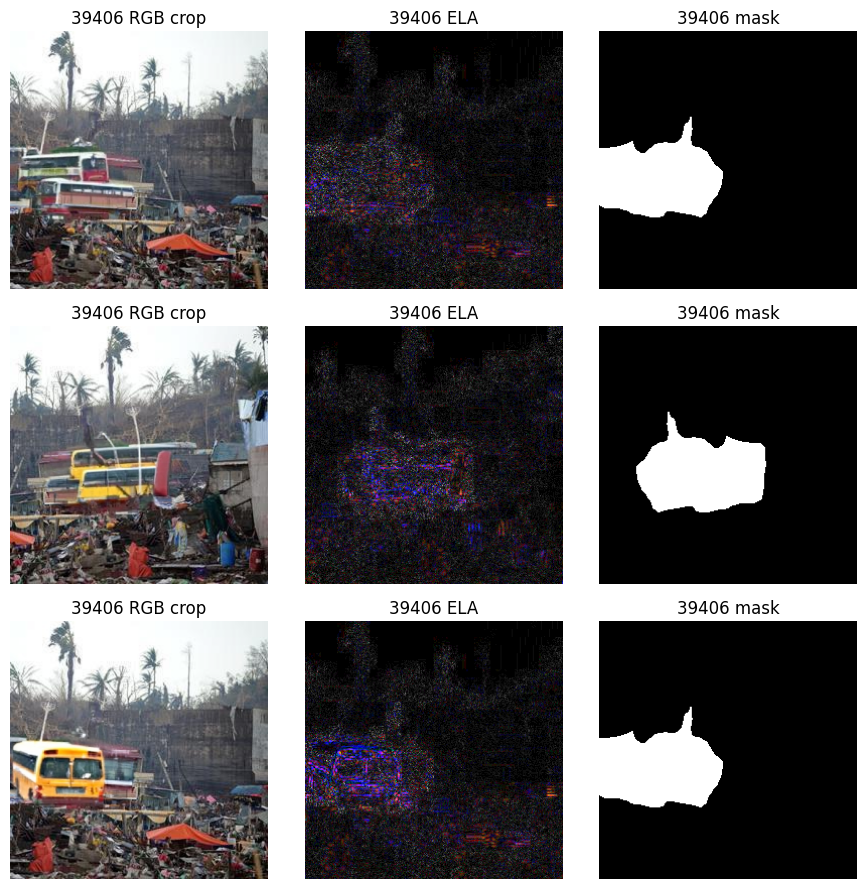

In [5]:
preview = CropDataset(train_records[:3], "rgb_ela", np.random.default_rng(seed))
figure, axes = plt.subplots(len(preview), 3, figsize=(9, 3 * len(preview)))
for row, (x, y) in enumerate(preview):
    rgb = (x[:3].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1)
    ela = (x[3:].numpy().transpose(1, 2, 0) * imagenet_std + imagenet_mean).clip(0, 1)
    for column, (image, title) in enumerate([(rgb, "RGB crop"), (ela, "ELA"), (y[0].numpy(), "mask")]):
        axes[row, column].imshow(image, cmap="gray" if column == 2 else None, vmin=0, vmax=1)
        axes[row, column].set_title(f"{preview.records[row]['original_id']} {title}")
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 4. ResNet-50 U-Net

인코더는 torchvision ResNet-50의 ImageNet 가중치를 사용함. conv1(1/2)·layer1(1/4)·layer2(1/8)·layer3(1/16)·layer4(1/32)의 특징을 디코더에 연결하고 마지막에 입력 크기로 되돌림. 입력 높이·너비는 32의 배수여야 함.

입력 채널 수 외에는 세 모델의 구조가 같음. 6채널 모델의 conv1은 제안서대로 RGB 가중치를 ELA 채널에 복사함. 복사 후 크기 조정 여부는 T06에서 정함. ELA 3채널 모델은 RGB용 conv1 가중치를 그대로 사용함.

In [6]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.block(x)


class ResNet50UNet(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        if in_channels == 6:
            rgb_weight = encoder.conv1.weight.detach().clone()
            encoder.conv1 = nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                encoder.conv1.weight.copy_(torch.cat([rgb_weight, rgb_weight], dim=1))
        elif in_channels != 3:
            raise ValueError("입력 채널은 3 또는 6이어야 함.")
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.layers = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoders = nn.ModuleList([
            DecoderBlock(2048, 1024, 256), DecoderBlock(256, 512, 128), DecoderBlock(128, 256, 64),
            DecoderBlock(64, 64, 32), DecoderBlock(32, 0, 16),
        ])
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        if x.shape[-2] % 32 or x.shape[-1] % 32:
            raise ValueError("입력 높이·너비는 32의 배수여야 함.")
        stem = self.stem(x)
        features = []
        out = self.pool(stem)
        for layer in self.layers:
            out = layer(out)
            features.append(out)
        out = features[-1]
        for decoder, skip in zip(self.decoders, [features[2], features[1], features[0], stem, None]):
            out = decoder(out, skip)
        return self.head(out)


reference_conv1 = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2).conv1.weight
summary = []
for mode, channels in input_channels.items():
    model = ResNet50UNet(channels).to(device).eval()
    weight = model.stem[0].weight.detach().cpu()
    assert torch.equal(weight[:, :3], reference_conv1)
    if channels == 6:
        assert torch.equal(weight[:, 3:], reference_conv1)
    with torch.no_grad():
        for shape in [(2, channels, 256, 256), (1, channels, 256, 384)]:
            output = model(torch.randn(shape, device=device))
            assert output.shape == (shape[0], 1, shape[2], shape[3]) and output.dtype == torch.float32
    summary.append(dict(mode=mode, in_channels=channels, parameters=sum(p.numel() for p in model.parameters()),
                        conv1_weight=tuple(weight.shape), output_check="통과"))
    del model
display(pd.DataFrame(summary))
print("세 입력 구성의 출력 크기·자료형·conv1 초기화 확인")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 242MB/s]


,mode,in_channels,parameters,conv1_weight,output_check
0,rgb,3,32520977,"(64, 3, 7, 7)",통과
1,ela,3,32520977,"(64, 3, 7, 7)",통과
2,rgb_ela,6,32530385,"(64, 6, 7, 7)",통과


세 입력 구성의 출력 크기·자료형·conv1 초기화 확인


## 5. 손실과 작은 배치 학습

손실은 BCEWithLogits와 soft Dice를 1:1로 더함(임시값). Dice는 배치 전체 픽셀로 계산함. 최적화는 Adam, 학습률 1e-4.

- RGB 모델: 같은 배치 하나를 30번 학습해 손실이 줄어드는지 확인함(과적합 확인).
- ELA·RGB+ELA 모델: 두 번만 학습해 역전파·최적화가 오류 없이 도는지 확인함.
- 각 모델에서 검증 단계(`eval`, `no_grad`)의 손실도 계산함.

rgb: 30 step, 1.6s, 첫 손실 1.3983 → 마지막 0.9601, 검증 손실 1.6065
ela: 2 step, 0.1s, 첫 손실 1.3910 → 마지막 1.3623, 검증 손실 1.7182
rgb_ela: 2 step, 0.1s, 첫 손실 1.3180 → 마지막 1.2916, 검증 손실 1.5009
RGB 모델의 같은 배치 반복 학습에서 손실 감소 확인


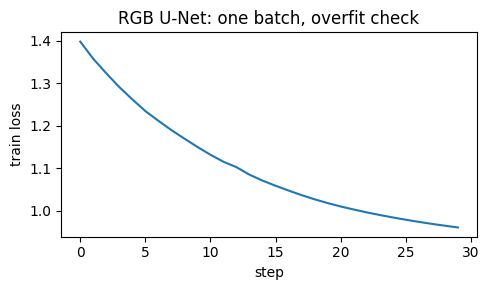

In [7]:
def dice_loss(logits, target, eps=1.0):
    probability = torch.sigmoid(logits)
    intersection = (probability * target).sum()
    return 1 - (2 * intersection + eps) / (probability.sum() + target.sum() + eps)


def loss_fn(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target) + dice_loss(logits, target)


def make_loader(records, mode, shuffle):
    generator = torch.Generator().manual_seed(seed)
    return torch.utils.data.DataLoader(CropDataset(records, mode, np.random.default_rng(seed)),
                                       batch_size=config["batch_size"], shuffle=shuffle, generator=generator)


def validate(model, mode):
    model.eval()
    losses = []
    with torch.no_grad():
        for x, y in make_loader(val_records, mode, shuffle=False):
            losses.append(loss_fn(model(x.to(device)), y.to(device)).item())
    return float(np.mean(losses))


training_log = []
models = {}
for mode, channels in input_channels.items():
    set_seed(seed)
    model = ResNet50UNet(channels).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    x, y = next(iter(make_loader(train_records, mode, shuffle=True)))
    x, y = x.to(device), y.to(device)
    steps = config["overfit_steps"] if mode == "rgb" else config["smoke_steps"]
    model.train()
    start = time.perf_counter()
    for step in range(1, steps + 1):
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        if not torch.isfinite(loss):
            raise RuntimeError(f"손실이 유한해야 함: {mode} step {step}")
        training_log.append(dict(mode=mode, step=step, loss=loss.item()))
    elapsed = time.perf_counter() - start
    print(f"{mode}: {steps} step, {elapsed:.1f}s, 첫 손실 {training_log[-steps]['loss']:.4f} → 마지막 {loss.item():.4f}, "
          f"검증 손실 {validate(model, mode):.4f}")
    models[mode] = model

log = pd.DataFrame(training_log)
rgb_log = log[log["mode"] == "rgb"]["loss"].to_numpy()
assert rgb_log[-5:].mean() < rgb_log[:5].mean(), "같은 배치를 반복 학습하면 손실이 줄어야 함"
print("RGB 모델의 같은 배치 반복 학습에서 손실 감소 확인")

plt.figure(figsize=(5, 3))
plt.plot(rgb_log)
plt.xlabel("step")
plt.ylabel("train loss")
plt.title("RGB U-Net: one batch, overfit check")
plt.tight_layout()
plt.show()

## 6. 체크포인트 저장·재로드

최적화 상태는 빼고 모델 가중치와 설정만 `/content/checkpoints`에 임시로 저장함. 모델 출력 저장 구조는 T16에서 정할 일이므로 Drive나 Git에는 저장하지 않음. 새 모델에 불러온 뒤 같은 입력의 예측이 같은지 확인함.

In [8]:
checkpoint_root.mkdir(parents=True, exist_ok=True)
for mode, channels in input_channels.items():
    path = checkpoint_root / f"EXP_kimjihwan_001_{mode}.pt"
    torch.save({"mode": mode, "in_channels": channels, "config": config, "state_dict": models[mode].state_dict()}, path)
    checkpoint = torch.load(path, map_location=device)
    restored = ResNet50UNet(checkpoint["in_channels"]).to(device)
    restored.load_state_dict(checkpoint["state_dict"])
    models[mode].eval()
    restored.eval()
    x, _ = next(iter(make_loader(val_records, mode, shuffle=False)))
    with torch.no_grad():
        difference = (models[mode](x.to(device)) - restored(x.to(device))).abs().max().item()
    print(f"{mode}: {path.name} {path.stat().st_size / 1024**2:.1f} MiB, 재로드 예측 최대 차이 {difference:.2e}")
    assert difference <= 1e-5
    del restored
print("세 모델의 체크포인트 재로드 예측 일치 확인")

rgb: EXP_kimjihwan_001_rgb.pt 124.4 MiB, 재로드 예측 최대 차이 0.00e+00
ela: EXP_kimjihwan_001_ela.pt 124.4 MiB, 재로드 예측 최대 차이 0.00e+00
rgb_ela: EXP_kimjihwan_001_rgb_ela.pt 124.4 MiB, 재로드 예측 최대 차이 0.00e+00
세 모델의 체크포인트 재로드 예측 일치 확인


## 7. 원본 해상도 추론과 공통 평가 함수 연결

검증 표본을 크롭 없이 원본 크기로 읽고, 원본 RGB에서 ELA를 계산한 뒤 32의 배수로 반사 패딩해 추론함. 예측을 원래 크기로 잘라 sigmoid·임계값 0.5를 적용하고 공통 평가 함수로 계산함. 패딩 방식은 임시값이며 T06에서 정해야 함.

조작 이미지는 F1·IoU, 정상 이미지는 픽셀 오탐률만 계산함(`tp + fn`으로 구분). **몇 번만 학습한 모델이므로 아래 값은 성능이 아니라 연결 확인용임.**

In [9]:
def predict_full(model, rgb, mode):
    height, width = rgb.shape[:2]
    multiple = config["pad_multiple"]
    x = to_input(rgb, ela_of(rgb), mode)[None].to(device)
    pad_bottom, pad_right = (-height) % multiple, (-width) % multiple
    x = F.pad(x, (0, pad_right, 0, pad_bottom), mode=config["pad_mode"])
    with torch.no_grad():
        probability = torch.sigmoid(model(x))[0, 0, :height, :width]
    return probability.cpu().numpy()


evaluation_rows = []
examples = {}
for mode in input_channels:
    models[mode].eval()
    for record in val_records:
        rgb, mask = load_pair(record)
        probability = predict_full(models[mode], rgb, mode)
        assert probability.shape == mask.shape
        prediction = (probability >= config["threshold"]).astype(np.uint8)
        tp, fp, fn, tn = confusion_counts(mask, prediction)
        row = dict(mode=mode, kind=record["kind"], original_id=record["original_id"], size=f"{mask.shape[0]}x{mask.shape[1]}",
                   tp=tp, fp=fp, fn=fn, tn=tn, f1=None, iou=None, fpr=None)
        if tp + fn > 0:
            row.update(f1=pixel_f1(tp, fp, fn), iou=iou(tp, fp, fn))
        else:
            row.update(fpr=false_positive_rate(fp, tn))
        evaluation_rows.append(row)
        if mode == "rgb":
            examples[record["original_id"] + "_" + record["kind"]] = (rgb, mask, probability)

evaluation = pd.DataFrame(evaluation_rows)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 200):
    display(evaluation)
    display(evaluation.groupby("mode").agg(manipulated_f1=("f1", "mean"), manipulated_iou=("iou", "mean"),
                                           normal_fpr=("fpr", "mean")))
assert evaluation.loc[evaluation.kind == "manipulated", "f1"].notna().all()
assert evaluation.loc[evaluation.kind == "normal", "fpr"].notna().all()
print("원본 해상도 추론과 공통 평가 함수 연결 확인. 위 값은 모델 성능이 아님")

,mode,kind,original_id,size,tp,fp,fn,tn,f1,iou,fpr
0,rgb,manipulated,39553,256x383,4412,39931,481,53224,0.179218,0.098429,NaN
1,rgb,manipulated,39553,256x383,2099,39980,2794,53175,0.089372,0.046776,NaN
2,rgb,manipulated,39553,256x383,4550,40731,343,52424,0.181369,0.099728,NaN
3,rgb,manipulated,39658,342x256,1510,1645,24772,59625,0.102592,0.054070,NaN
4,rgb,normal,39553,256x383,0,41978,0,56070,NaN,NaN,0.428137
5,rgb,normal,39658,342x256,0,2081,0,85471,NaN,NaN,0.023769
6,rgb,normal,39683,320x256,0,34217,0,47703,NaN,NaN,0.417688
7,rgb,normal,39969,256x422,0,6663,0,101369,NaN,NaN,0.061676
8,ela,manipulated,39553,256x383,4893,93155,0,0,0.095064,0.049904,NaN
9,ela,manipulated,39553,256x383,4893,93155,0,0,0.095064,0.049904,NaN


,manipulated_f1,manipulated_iou,normal_fpr
mode,,,
ela,0.186738,0.112475,1.000000
rgb,0.138138,0.074751,0.232818
rgb_ela,0.000000,0.000000,0.000000


원본 해상도 추론과 공통 평가 함수 연결 확인. 위 값은 모델 성능이 아님


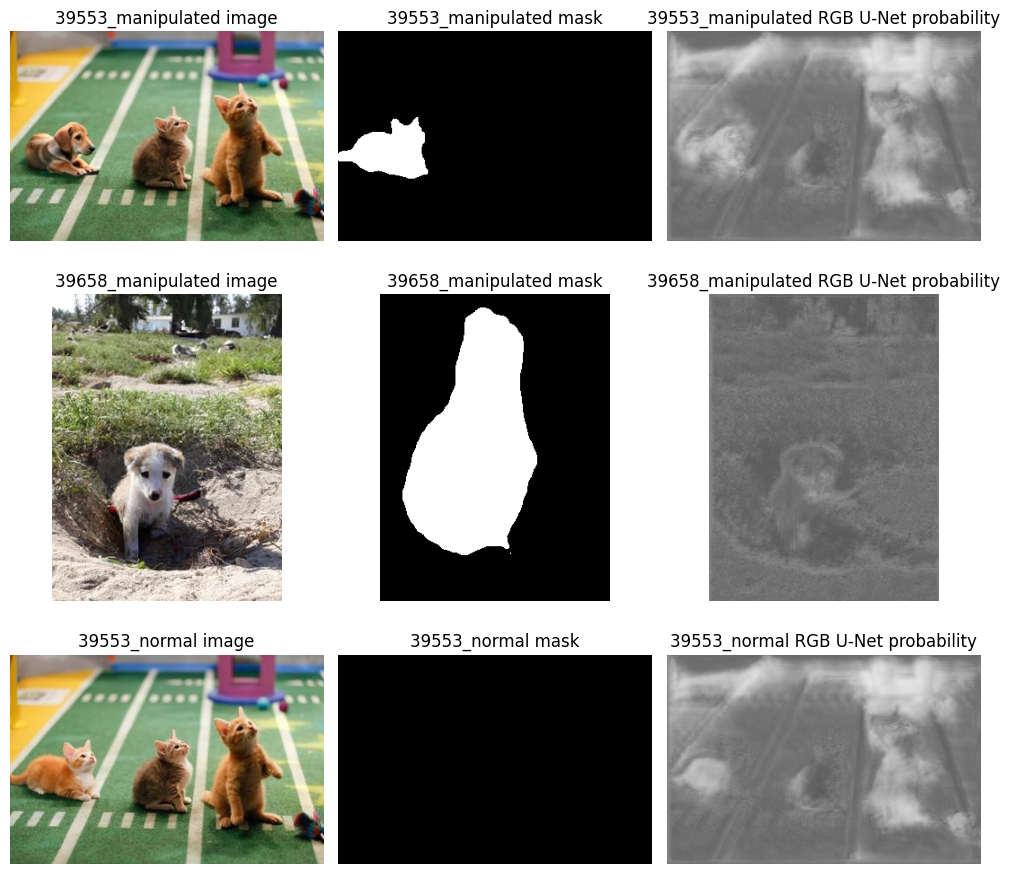

In [10]:
shown = list(examples.items())[:2] + [item for item in examples.items() if item[0].endswith("_normal")][:1]
figure, axes = plt.subplots(len(shown), 3, figsize=(10, 3.2 * len(shown)))
for row, (name, (rgb, mask, probability)) in enumerate(shown):
    for column, (image, title) in enumerate([(rgb, "image"), (mask, "mask"), (probability, "RGB U-Net probability")]):
        axes[row, column].imshow(image, cmap=None if column == 0 else "gray", vmin=0, vmax=1 if column else None)
        axes[row, column].set_title(f"{name} {title}")
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 8. 확인 결과와 검토 메모

아래 셀이 오류 없이 끝나면 T03 검증 항목 다섯 가지가 이 런타임에서 동작한 것임. 버전·GPU·실행 시간은 1·5절 출력을 기록함. 학습 조건·성능은 확인 범위가 아님.

사람 검토 메모(실행 후 작성):

- 3절 그림의 크롭·ELA·마스크 위치 대응:
- 7절 그림의 예측 확률 표시와 원본 크기 대응:
- 특이사항(실행 시간, 메모리 부족 등):

In [11]:
checks = [
    "torch·torchvision import와 ImageNet ResNet-50 가중치 로드",
    "rgb·ela·rgb_ela 입력의 예측 크기·채널·자료형",
    "같은 배치 반복 학습의 손실 감소와 세 모델의 역전파·검증 단계",
    "세 모델의 체크포인트 저장·재로드 예측 일치",
    "원본 해상도 추론과 공통 평가 함수 연결",
]
for item in checks:
    print("확인:", item)
print("동작 확인 완료. 기본 비교 실험의 학습 조건·성능은 확인하지 않음")

확인: torch·torchvision import와 ImageNet ResNet-50 가중치 로드
확인: rgb·ela·rgb_ela 입력의 예측 크기·채널·자료형
확인: 같은 배치 반복 학습의 손실 감소와 세 모델의 역전파·검증 단계
확인: 세 모델의 체크포인트 저장·재로드 예측 일치
확인: 원본 해상도 추론과 공통 평가 함수 연결
동작 확인 완료. 기본 비교 실험의 학습 조건·성능은 확인하지 않음


3절: 39406 조작본 3장에서 크롭 위치에 따라 마스크가 함께 이동하고 버스 위치와 대응함. 3번째 크롭의 ELA에 버스 윤곽이 보임. 표본이 한 원본에 몰려 있음.  
7절: 예측 확률이 원본 크기로 출력됨. 학습량이 적어 조작 영역을 구분하지 못함(성능 아님).